# Calculate the SED for G54.1+0.3

This notebook builds the Gelfand, Slane & Zhang (2009) PWN model for
**G54.1+0.3 (PSR J1930+1852)** at its published best-fit parameters
[Alford, Zhang & Gelfand (2025)](https://arxiv.org/abs/2506.22409).

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt

from viper import PWNModel
from viper.plotting import plot_model_sed

## 1. Run the model

In [2]:
model = PWNModel()
model.set_pulsar('J1930+1852')      # G54.1 pulsar: loads P, Pdot
model.distance.value      = 6.22 * u.kpc
model.esn.value           = 0.95e51 * u.erg
model.mej.value           = 21.0 * u.M_sun
model.n_ism.value         = 0.008 / u.cm**3
model.braking_index.value = 1.9
model.tau_sd.value        = 3574 * u.yr
model.eta_b.value         = 2.4e-3
model.e_min.value         = 10.0 * u.GeV
model.e_max.value         = 400 * u.TeV
model.e_break.value       = 3.23 * u.TeV
model.p1.value, model.p2.value = 2.29, 2.42
model.add_ic_field(temp=2753, norm=23.6137)   # NIR dust field [eV/cm^3]

result = model.run(dyn_step=10)

## 2. Multiwavelength flux points

Published $\nu F_\nu = E^2\,dN/dE$ points (radio $\to$ 50 TeV). The two
Fermi-LAT entries flagged as upper limits are drawn as downward arrows.

In [3]:
# E [TeV], nuFnu [erg/cm^2/s], err, upper_limit, instrument
data = [
    (6.2035e-19, 6.9600e-16, 7.0500e-17, False, 'LOFAR/VLA'),
    (5.7899e-18, 6.0620e-15, 4.2000e-16, False, 'LOFAR/VLA'),
    (1.9438e-17, 1.5369e-14, 1.1750e-15, False, 'LOFAR/VLA'),
    (3.5153e-17, 2.1420e-14, 1.7000e-15, False, 'LOFAR/VLA'),
    (4.2426e-09, 3.3177e-12, 1.5867e-13, False, 'XMM/NuSTAR'),
    (1.3416e-08, 2.3520e-12, 6.7550e-14, False, 'XMM/NuSTAR'),
    (5.3542e-04, 1.4422e-12, 0.0000e+00, True,  'Fermi-LAT'),
    (1.7055e-03, 1.0392e-12, 3.7280e-13, False, 'Fermi-LAT'),
    (5.4323e-03, 6.2883e-13, 2.6477e-13, False, 'Fermi-LAT'),
    (1.7303e-02, 9.7379e-13, 3.2140e-13, False, 'Fermi-LAT'),
    (5.5116e-02, 2.4822e-12, 0.0000e+00, True,  'Fermi-LAT'),
    (1.7556e-01, 1.3185e-12, 1.0321e-12, False, 'Fermi-LAT'),
    (3.1100e-01, 1.7046e-12, 8.6780e-13, False, 'VERITAS'),
    (4.9200e-01, 1.6289e-12, 5.4296e-13, False, 'VERITAS'),
    (7.8000e-01, 1.0917e-12, 4.3864e-13, False, 'VERITAS'),
    (1.2000e+00, 1.4304e-12, 3.9221e-13, False, 'VERITAS'),
    (3.0000e+00, 4.4701e-13, 3.0281e-13, False, 'VERITAS'),
    (5.0000e+01, 2.5635e-13, 2.4033e-14, False, 'LHAASO'),
]

## 3. Plot the model and data

`plot_model_sed` draws the photon SED (black) and the evolved electron
spectrum (faint blue, upper axis).

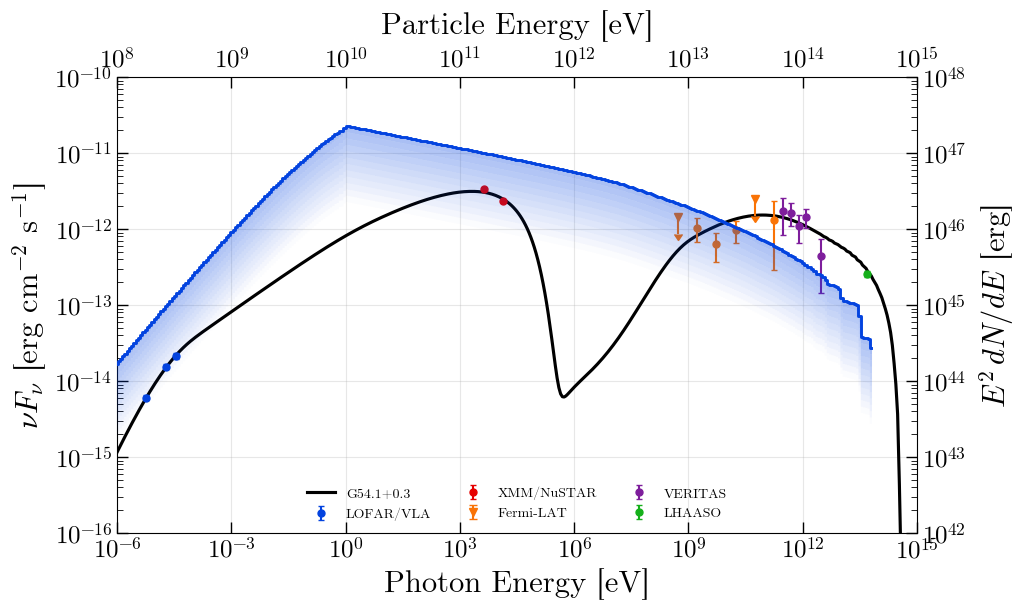

In [4]:
fig, axd = plot_model_sed(result, distance=model.distance.value,
                          model_label='G54.1+0.3')
ax = axd['sed']

colors = {'LOFAR/VLA': 'xkcd:blue',  'XMM/NuSTAR': 'xkcd:red',
          'Fermi-LAT': 'xkcd:orange', 'VERITAS': 'xkcd:purple',
          'LHAASO': 'xkcd:green'}

seen = set()
for e_tev, nufnu, err, is_ul, inst in data:
    e_ev = e_tev * 1e12
    label = inst if inst not in seen else None
    seen.add(inst)
    if is_ul:
        ax.errorbar(e_ev, nufnu, yerr=0.4 * nufnu, uplims=True,
                    color=colors[inst], marker='v', ms=6, ls='none',
                    label=label, zorder=6)
    else:
        ax.errorbar(e_ev, nufnu, yerr=err, color=colors[inst], marker='o',
                    ms=5, ls='none', capsize=2, label=label, zorder=6)

ax.legend(loc='lower center', ncol=3, frameon=False, fontsize=10)
plt.show()